In [1]:
print("Hello, EDA Project!")

Hello, EDA Project!


# Exploratory Data Analysis of House Prices

## 1. Introduction

This project focuses on Exploratory Data Analysis (EDA) of the Ames Housing Dataset. The dataset contains information about residential properties, including their size, quality, location, construction year and sale price.

The main objective of this project is to understand the factors affecting house prices through statistical analysis and data visualization.

We will use Python libraries such as Pandas, NumPy, Matplotlib, Seaborn and SciPy. This project focuses on data analysis and does not involve machine learning.

## Project Objectives

- Understand the structure of the dataset.
- Analyze numerical and categorical variables.
- Study the distribution of house prices.
- Identify features correlated with SalePrice.
- Detect outliers and missing values.
- Create meaningful visualizations.
- Build a final EDA dashboard.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Dataset

In this section, we load the Ames Housing dataset using Pandas. We will examine the dataset dimensions and display the first five rows to understand the structure of the data.

In [4]:
df = pd.read_csv("../data/train.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Initial Data Inspection

In this section, we inspect the dataset to understand its dimensions, column names, data types, memory usage and the presence of duplicate records.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [6]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1460
Number of Columns: 81


In [7]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0


In [8]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolA

### 3.1 Missing Values Analysis

Missing values occur when information is not available for certain observations. In this section, we identify columns containing missing values and calculate their percentages.

In [9]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing_df = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df)) * 100
})

display(missing_df)

,Missing Values,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


# 4. Variable Classification

Variables in the dataset can be classified into numerical and categorical variables. Numerical variables represent measurable quantities, while categorical variables represent groups or labels.

In this section, we separate numerical and categorical columns to understand the dataset better.

In [10]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Number of Numerical Columns:", len(numerical_columns))
print("\nNumerical Columns:")
print(numerical_columns)

Number of Numerical Columns: 38

Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']


In [12]:
categorical_columns = df.select_dtypes(include=["object", "str"]).columns.tolist()

print("Number of Categorical Columns:", len(categorical_columns))
print("\nCategorical Columns:")
print(categorical_columns)

Number of Categorical Columns: 43

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [13]:
print("Total Columns:", len(df.columns))
print("Numerical Columns:", len(numerical_columns))
print("Categorical Columns:", len(categorical_columns))
print("Total Classified Columns:", len(numerical_columns) + len(categorical_columns))

Total Columns: 81
Numerical Columns: 38
Categorical Columns: 43
Total Classified Columns: 81


## 4.1 Visualizing Missing Values

We use a bar chart to identify the columns with the highest number of missing values. This helps us understand the extent of missing data in the dataset.

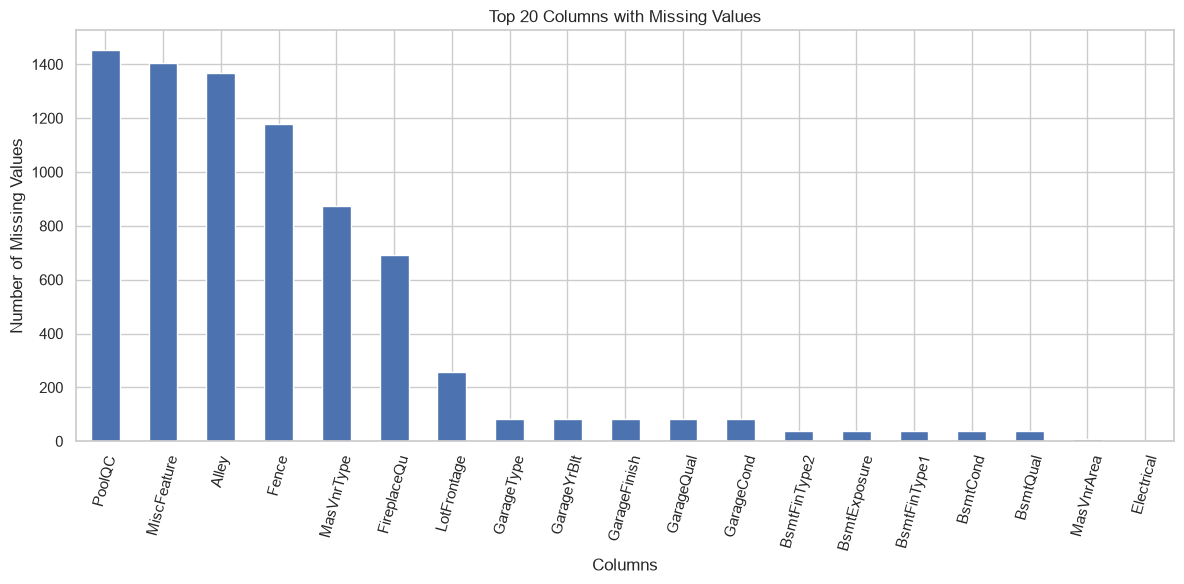

In [14]:
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

plt.figure(figsize=(12, 6))
missing_counts.head(20).plot(kind="bar")

plt.title("Top 20 Columns with Missing Values")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 4.2 Preparing the Working Dataset

We create a copy of the original dataset to perform cleaning without modifying the original data. Some missing values represent the absence of a feature, such as a garage, fence or pool.

In [15]:
df_eda = df.copy()

print("Working dataset created successfully!")
print("Working dataset shape:", df_eda.shape)

Working dataset created successfully!
Working dataset shape: (1460, 81)


### 4.3 Handling Structural Missing Values

Some categorical missing values represent the absence of property features. For example, a missing pool quality value may mean that the property has no pool.

We replace these structural missing values with the label "None" to make their meaning clear.

In [16]:
absence_columns = [
    "Alley",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "PoolQC",
    "Fence",
    "MiscFeature"
]

for column in absence_columns:
    if column in df_eda.columns:
        df_eda[column] = df_eda[column].fillna("None")

print("Structural missing values handled.")

Structural missing values handled.


In [17]:
print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_eda.shape)

print("\nRemaining Missing Values:")
remaining_missing = df_eda.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0].sort_values(ascending=False)

display(remaining_missing)

Original Dataset Shape: (1460, 81)
Working Dataset Shape: (1460, 81)

Remaining Missing Values:


MasVnrType     872
LotFrontage    259
GarageYrBlt     81
MasVnrArea       8
Electrical       1
dtype: int64

# 5. Descriptive Statistical Analysis

Descriptive statistical analysis helps us understand the characteristics of the dataset using statistical measures. In this section, we calculate the mean, median, standard deviation, minimum, maximum and other statistical values to understand the numerical variables.

In [18]:
df_eda.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## 5.1 Sale Price Statistical Analysis

SalePrice is the target variable representing the selling price of houses. We analyze its statistical measures to understand the average price, variation and price range.

In [23]:
print("Mean Sale Price:", df_eda["SalePrice"].mean())
print("Median Sale Price:", df_eda["SalePrice"].median())
print("Mode Sale Price:", df_eda["SalePrice"].mode()[0])
print("Standard Deviation:", df_eda["SalePrice"].std())
print("Minimum Sale Price:", df_eda["SalePrice"].min())
print("Maximum Sale Price:", df_eda["SalePrice"].max())

Mean Sale Price: 180921.19589041095
Median Sale Price: 163000.0
Mode Sale Price: 140000
Standard Deviation: 79442.50288288662
Minimum Sale Price: 34900
Maximum Sale Price: 755000


### 5.2 Skewness and Kurtosis

Skewness measures the asymmetry of a data distribution. Kurtosis helps us understand the shape of the distribution and the presence of extreme values.

In [24]:
print("SalePrice Skewness:", df_eda["SalePrice"].skew())
print("SalePrice Kurtosis:", df_eda["SalePrice"].kurt())

SalePrice Skewness: 1.8828757597682129
SalePrice Kurtosis: 6.536281860064529


### 5.3 Distribution of Sale Prices

A histogram is used to visualize the distribution of house sale prices. It helps us identify the frequency of different price ranges and understand whether the distribution is symmetrical or skewed.


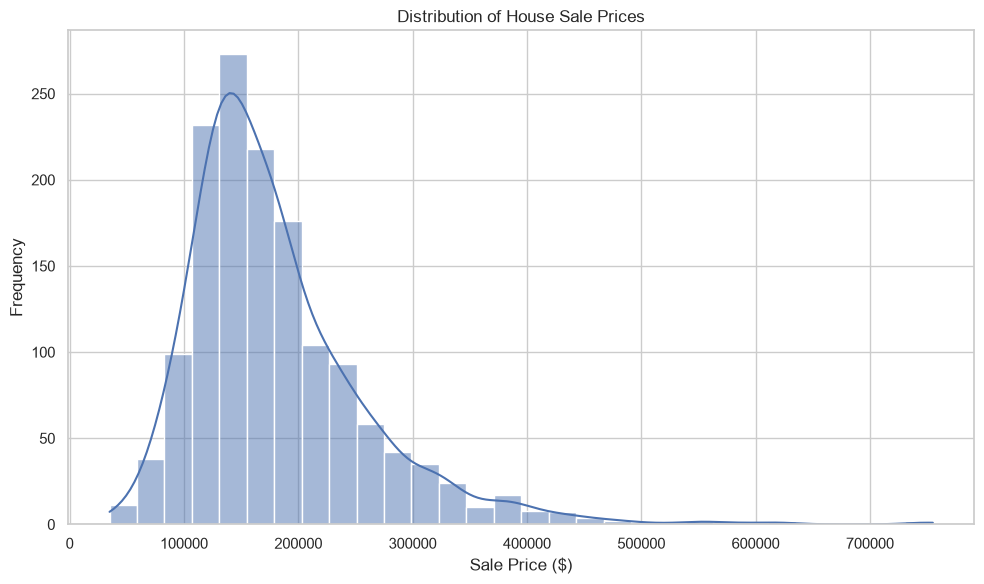

In [25]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df_eda, x="SalePrice", bins=30, kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### 5.4 Boxplot of Sale Prices

A boxplot is used to identify the median, spread and potential outliers in the house sale prices.

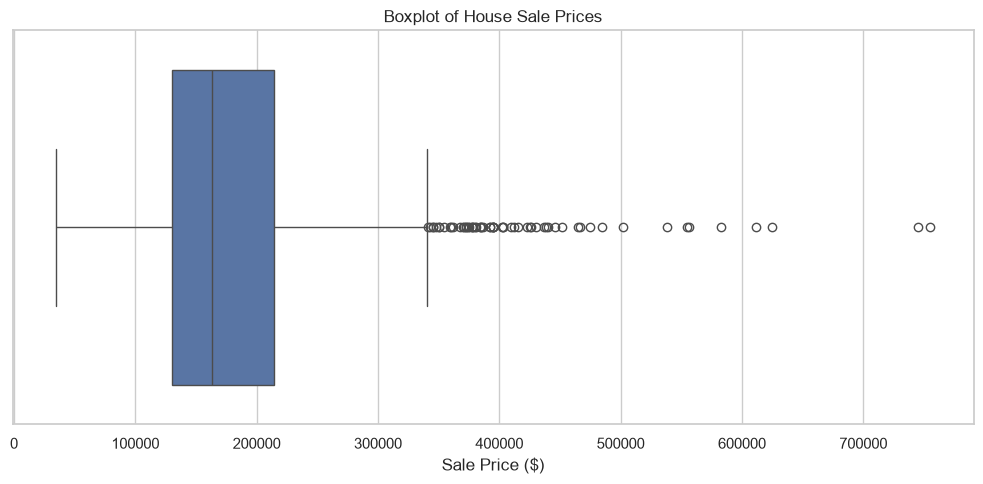

In [26]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_eda["SalePrice"])

plt.title("Boxplot of House Sale Prices")
plt.xlabel("Sale Price ($)")

plt.tight_layout()
plt.show()

# 6. Univariate Analysis

Univariate analysis is the process of analyzing a single variable independently. It helps us understand the distribution, frequency, central tendency and patterns of individual variables.

In this section, we analyze important features of the Ames Housing Dataset using histograms, count plots and boxplots.

## 6.1 Analysis of Living Area (GrLivArea)

GrLivArea represents the above-ground living area in square feet. We analyze its distribution to understand the size of houses included in the dataset.

In [27]:
print("Mean Living Area:", df_eda["GrLivArea"].mean())
print("Median Living Area:", df_eda["GrLivArea"].median())
print("Minimum Living Area:", df_eda["GrLivArea"].min())
print("Maximum Living Area:", df_eda["GrLivArea"].max())

Mean Living Area: 1515.463698630137
Median Living Area: 1464.0
Minimum Living Area: 334
Maximum Living Area: 5642


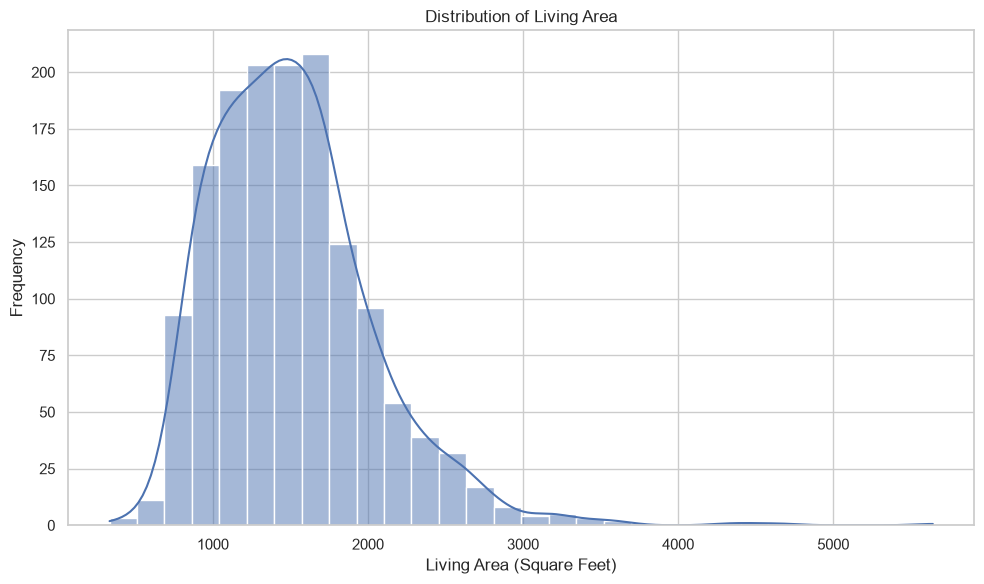

In [28]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df_eda, x="GrLivArea", bins=30, kde=True)

plt.title("Distribution of Living Area")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## 6.2 Analysis of Lot Area (LotArea)

LotArea represents the total land area of a property in square feet. We analyze its distribution to understand the sizes of residential plots in the dataset.

In [29]:
print("Mean Lot Area:", df_eda["LotArea"].mean())
print("Median Lot Area:", df_eda["LotArea"].median())
print("Minimum Lot Area:", df_eda["LotArea"].min())
print("Maximum Lot Area:", df_eda["LotArea"].max())

Mean Lot Area: 10516.828082191782
Median Lot Area: 9478.5
Minimum Lot Area: 1300
Maximum Lot Area: 215245


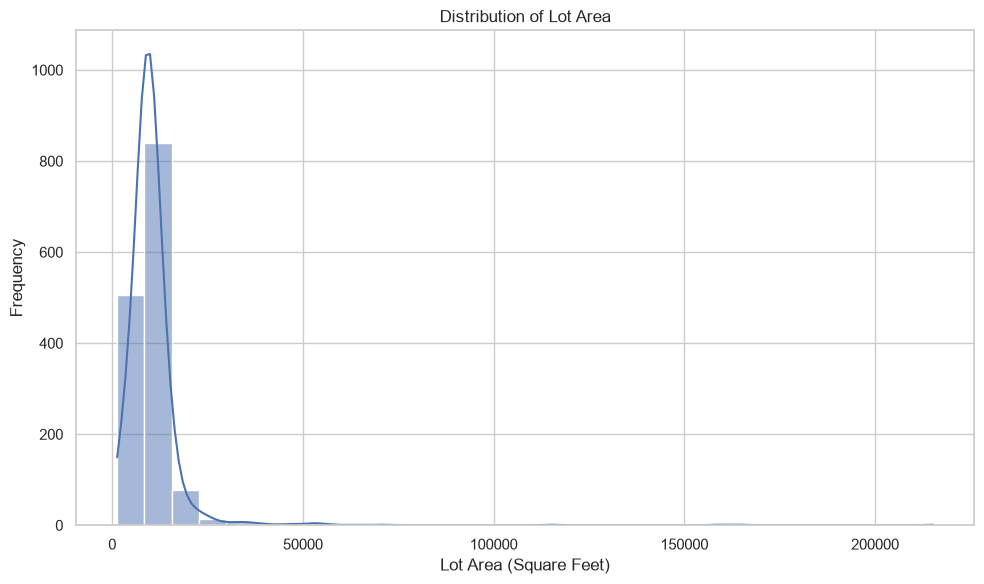

In [30]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df_eda, x="LotArea", bins=30, kde=True)

plt.title("Distribution of Lot Area")
plt.xlabel("Lot Area (Square Feet)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## 6.3 Analysis of Overall Quality (OverallQual)

OverallQual represents the overall quality of the house on a scale from 1 to 10. We use a count plot to understand how the quality ratings are distributed across the dataset.

In [31]:
print("Quality Rating Counts:")
display(df_eda["OverallQual"].value_counts().sort_index())

Quality Rating Counts:


OverallQual
1       2
2       3
3      20
4     116
5     397
6     374
7     319
8     168
9      43
10     18
Name: count, dtype: int64

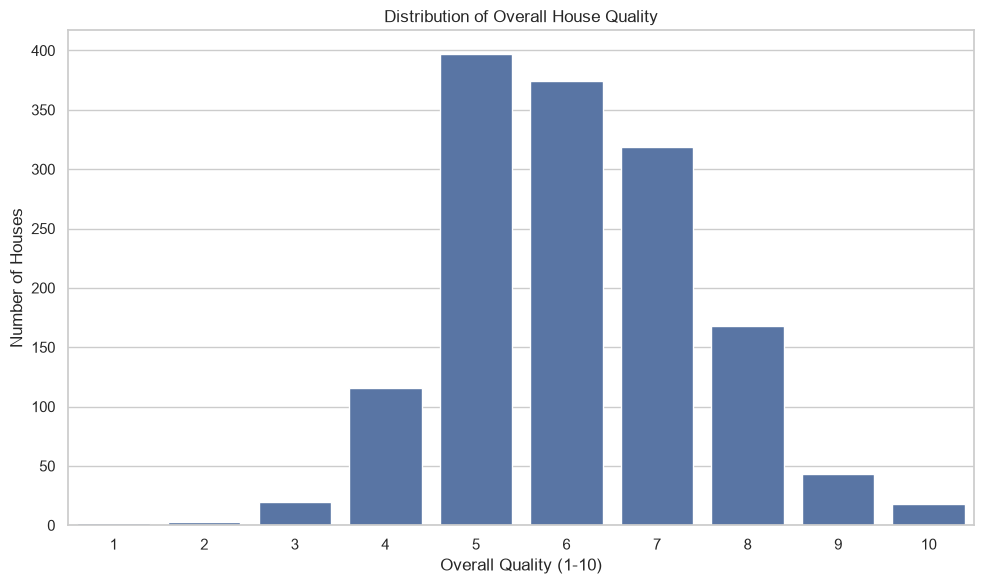

In [32]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df_eda, x="OverallQual")

plt.title("Distribution of Overall House Quality")
plt.xlabel("Overall Quality (1-10)")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

## 6.4 Analysis of Year Built

YearBuilt represents the original construction year of the house. We analyze this variable to understand the age and construction patterns of properties in the dataset.

In [33]:
print("Earliest Construction Year:", df_eda["YearBuilt"].min())
print("Latest Construction Year:", df_eda["YearBuilt"].max())
print("Median Construction Year:", df_eda["YearBuilt"].median())

Earliest Construction Year: 1872
Latest Construction Year: 2010
Median Construction Year: 1973.0


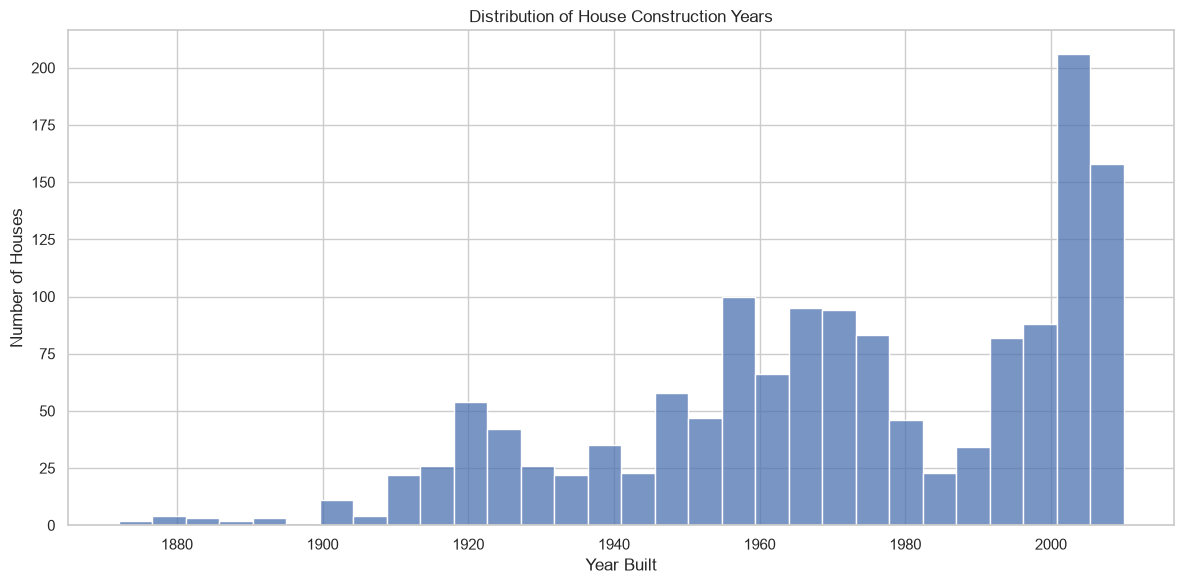

In [34]:
plt.figure(figsize=(12, 6))

sns.histplot(data=df_eda, x="YearBuilt", bins=30)

plt.title("Distribution of House Construction Years")
plt.xlabel("Year Built")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

## 6.5 Analysis of Bedrooms Above Ground

BedroomAbvGr represents the number of bedrooms above ground level. We use a count plot to understand the number of bedrooms commonly found in houses.

In [35]:
print("Bedroom Counts:")
display(df_eda["BedroomAbvGr"].value_counts().sort_index())

Bedroom Counts:


BedroomAbvGr
0      6
1     50
2    358
3    804
4    213
5     21
6      7
8      1
Name: count, dtype: int64

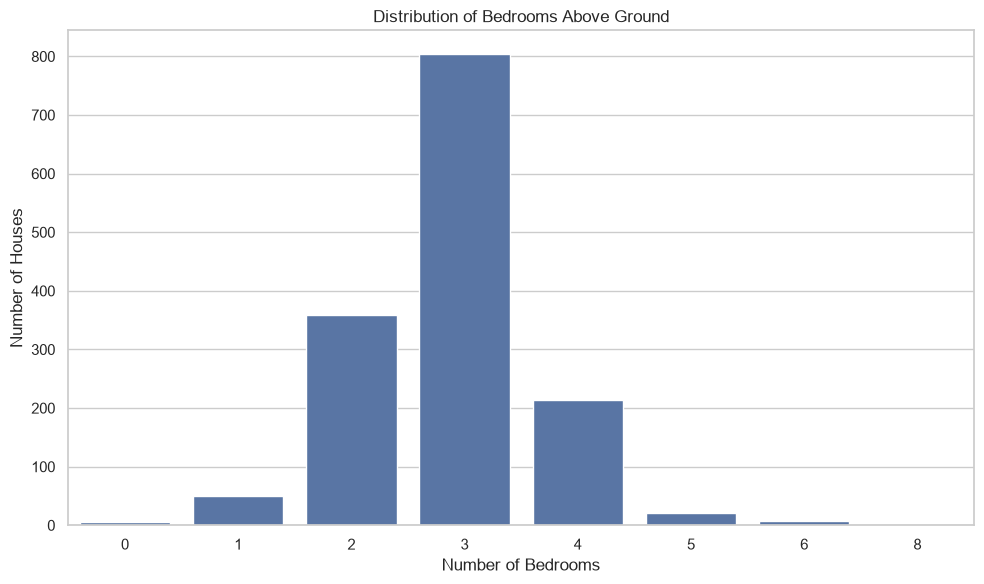

In [36]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df_eda, x="BedroomAbvGr")

plt.title("Distribution of Bedrooms Above Ground")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

## 6.6 Summary of Selected Variables

This summary provides a statistical overview of important housing variables selected for univariate analysis.

In [37]:
selected_columns = [
    "SalePrice",
    "GrLivArea",
    "LotArea",
    "OverallQual",
    "YearBuilt",
    "BedroomAbvGr"
]

display(df_eda[selected_columns].describe())

,SalePrice,GrLivArea,LotArea,OverallQual,YearBuilt,BedroomAbvGr
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,180921.195890,1515.463699,10516.828082,6.099315,1971.267808,2.866438
std,79442.502883,525.480383,9981.264932,1.382997,30.202904,0.815778
min,34900.000000,334.000000,1300.000000,1.000000,1872.000000,0.000000
25%,129975.000000,1129.500000,7553.500000,5.000000,1954.000000,2.000000
50%,163000.000000,1464.000000,9478.500000,6.000000,1973.000000,3.000000
75%,214000.000000,1776.750000,11601.500000,7.000000,2000.000000,3.000000
max,755000.000000,5642.000000,215245.000000,10.000000,2010.000000,8.000000


# 7. Bivariate Analysis

Bivariate analysis is used to study the relationship between two variables. In this section, we analyze how different house features relate to the SalePrice variable using scatter plots, boxplots and correlation analysis.

## 7.1 Living Area vs Sale Price

We analyze the relationship between the above-ground living area (GrLivArea) and SalePrice. A scatter plot helps us observe whether larger houses tend to have higher sale prices.

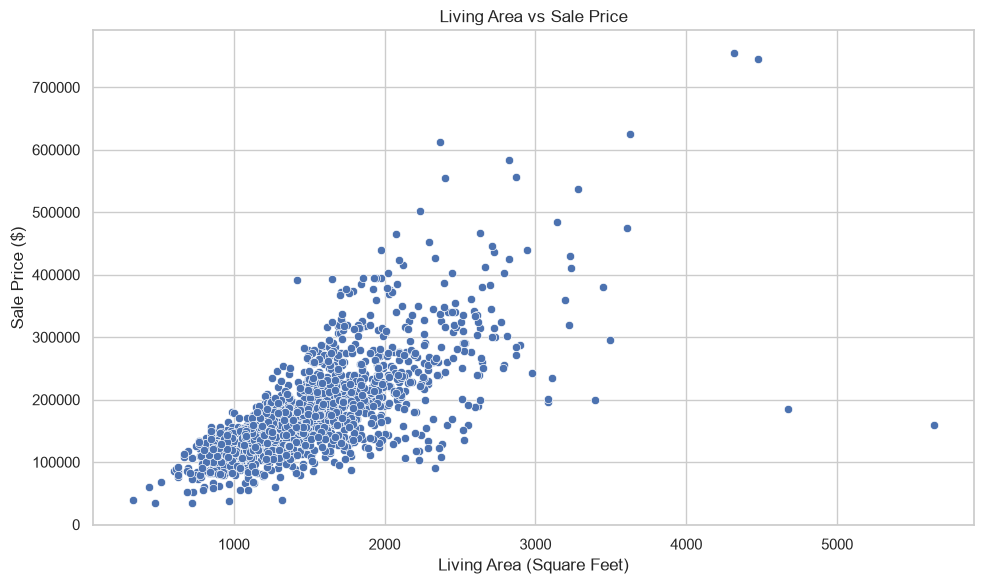

In [39]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df_eda, x="GrLivArea", y="SalePrice")

plt.title("Living Area vs Sale Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()

## 7.2 Overall Quality vs Sale Price

OverallQual represents the overall quality of the house. We use a boxplot to compare the distribution of sale prices across different quality ratings.

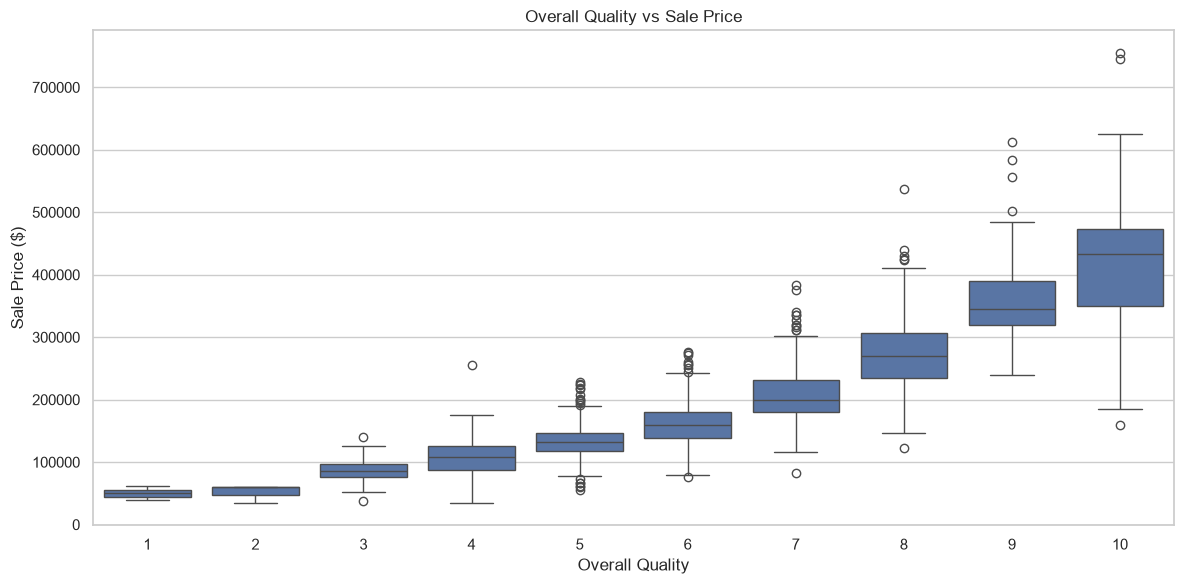

In [40]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_eda, x="OverallQual", y="SalePrice")

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()

## 7.3 Garage Area vs Sale Price

GarageArea represents the garage size in square feet. We use a scatter plot to examine the relationship between garage area and house sale price.

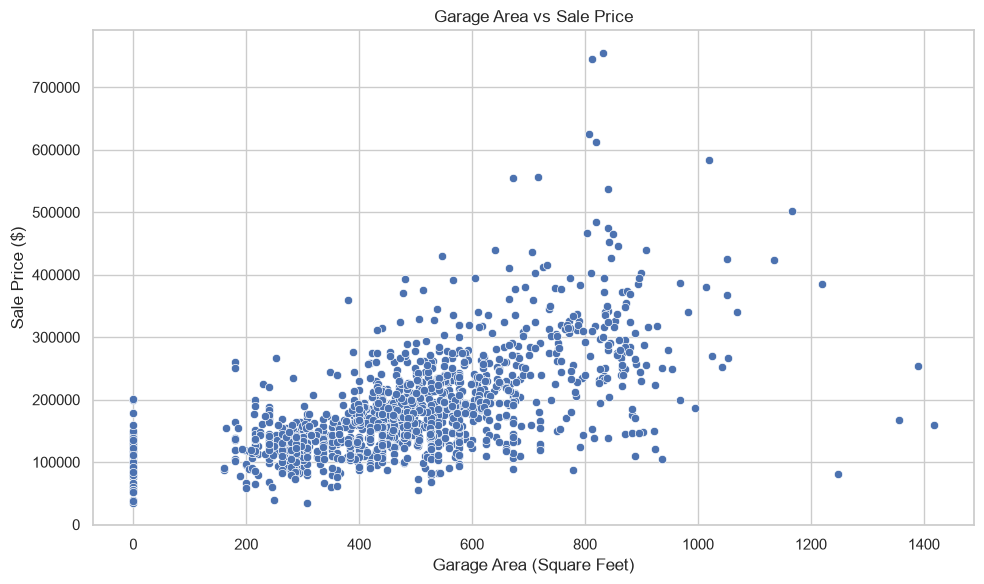

In [41]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df_eda, x="GarageArea", y="SalePrice")

plt.title("Garage Area vs Sale Price")
plt.xlabel("Garage Area (Square Feet)")
plt.ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()

## 7.4 Year Built vs Sale Price

YearBuilt represents the original construction year of a house. We use a scatter plot to observe how construction year relates to house sale prices.

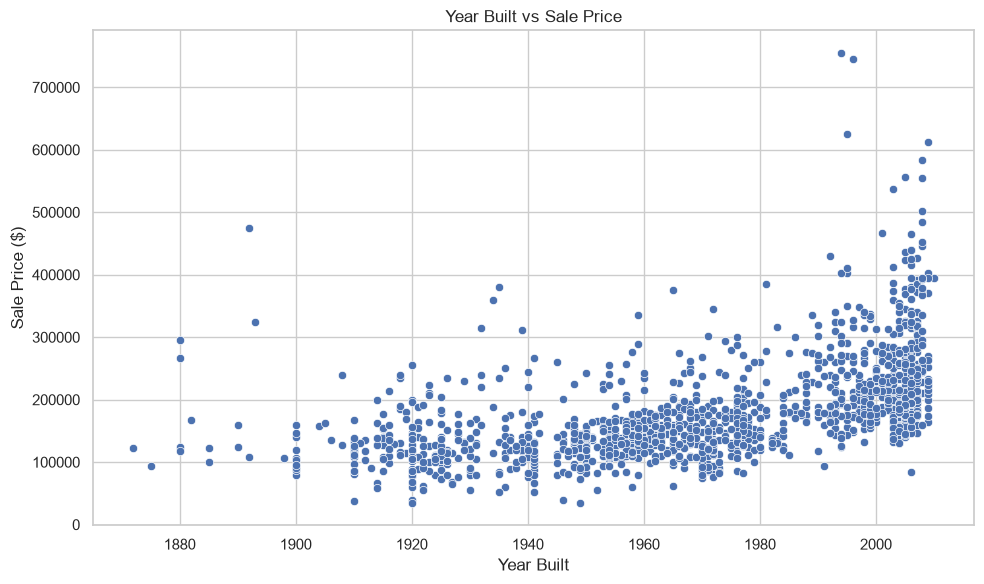

In [42]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df_eda, x="YearBuilt", y="SalePrice")

plt.title("Year Built vs Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()

## 7.5 Total Basement Area vs Sale Price

TotalBsmtSF represents the total basement area in square feet. We analyze its relationship with SalePrice using a scatter plot.


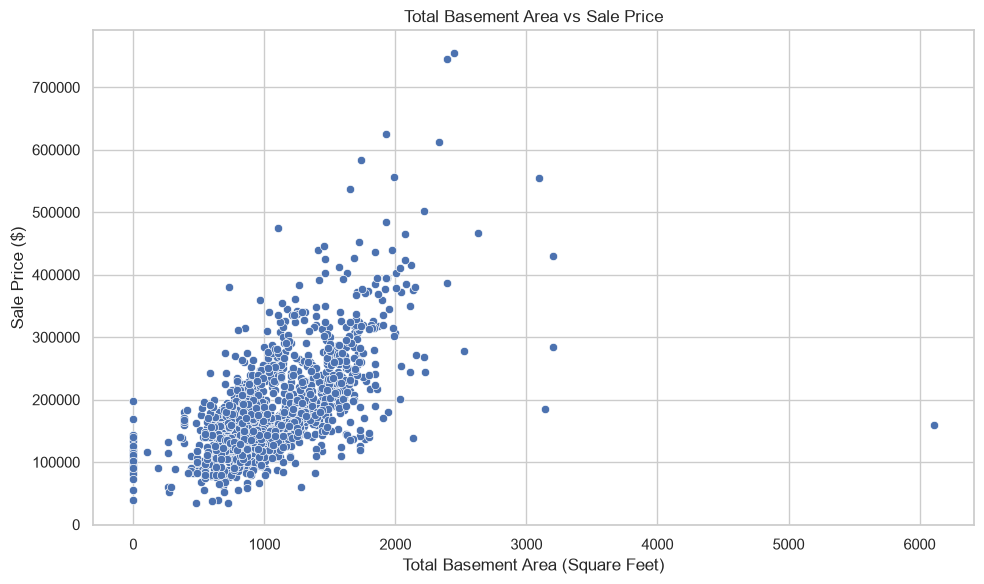

In [43]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df_eda, x="TotalBsmtSF", y="SalePrice")

plt.title("Total Basement Area vs Sale Price")
plt.xlabel("Total Basement Area (Square Feet)")
plt.ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()

## 7.6 Correlation Analysis

Correlation measures the strength and direction of the relationship between numerical variables. We use the Pearson correlation coefficient to examine relationships between selected house features and SalePrice.

In [44]:
correlation_features = [
    "SalePrice",
    "GrLivArea",
    "OverallQual",
    "GarageArea",
    "YearBuilt",
    "TotalBsmtSF"
]

correlation_matrix = df_eda[correlation_features].corr()

display(correlation_matrix)

,SalePrice,GrLivArea,OverallQual,GarageArea,YearBuilt,TotalBsmtSF
SalePrice,1.000000,0.708624,0.790982,0.623431,0.522897,0.613581
GrLivArea,0.708624,1.000000,0.593007,0.468997,0.199010,0.454868
OverallQual,0.790982,0.593007,1.000000,0.562022,0.572323,0.537808
GarageArea,0.623431,0.468997,0.562022,1.000000,0.478954,0.486665
YearBuilt,0.522897,0.199010,0.572323,0.478954,1.000000,0.391452
TotalBsmtSF,0.613581,0.454868,0.537808,0.486665,0.391452,1.000000


### 7.7 Correlation Heatmap

A heatmap provides a visual representation of the correlation between numerical variables. It helps us identify features that have stronger linear relationships with SalePrice.

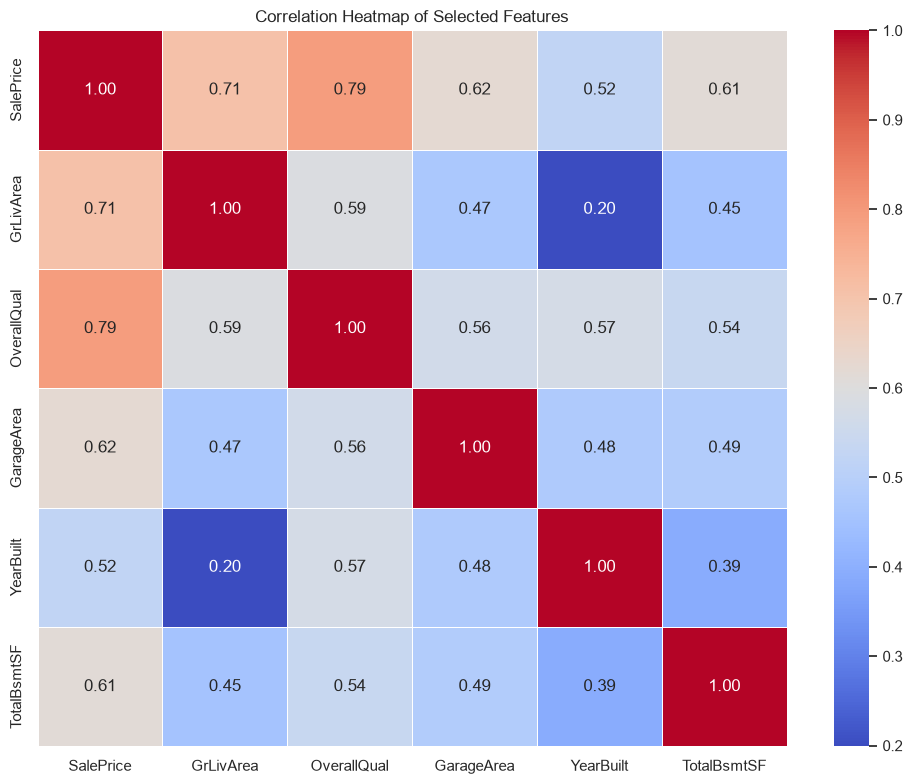

In [45]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Selected Features")

plt.tight_layout()
plt.show()

# 8. Outlier Detection & Analysis

Outliers are data points that are significantly different from the other observations in a dataset. In this stage, we identify potential outliers in house prices and living area using boxplots and the Interquartile Range (IQR) method.

## 8.1 Outlier Detection in SalePrice

We use the Interquartile Range (IQR) method to identify unusually high or low house prices. The IQR is calculated as the difference between the third quartile (Q3) and the first quartile (Q1).

In [46]:
Q1 = df_eda["SalePrice"].quantile(0.25)
Q3 = df_eda["SalePrice"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

price_outliers = df_eda[
    (df_eda["SalePrice"] < lower_bound) |
    (df_eda["SalePrice"] > upper_bound)
]

print("SalePrice Outlier Analysis")
print("-------------------------")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(price_outliers))

SalePrice Outlier Analysis
-------------------------
Q1: 129975.0
Q3: 214000.0
IQR: 84025.0
Lower Bound: 3937.5
Upper Bound: 340037.5
Number of Outliers: 61


## 8.2 SalePrice Outlier Visualization

A boxplot helps us visually identify potential outliers in the SalePrice variable. Points outside the whiskers are potential outliers according to the boxplot's statistical rule.

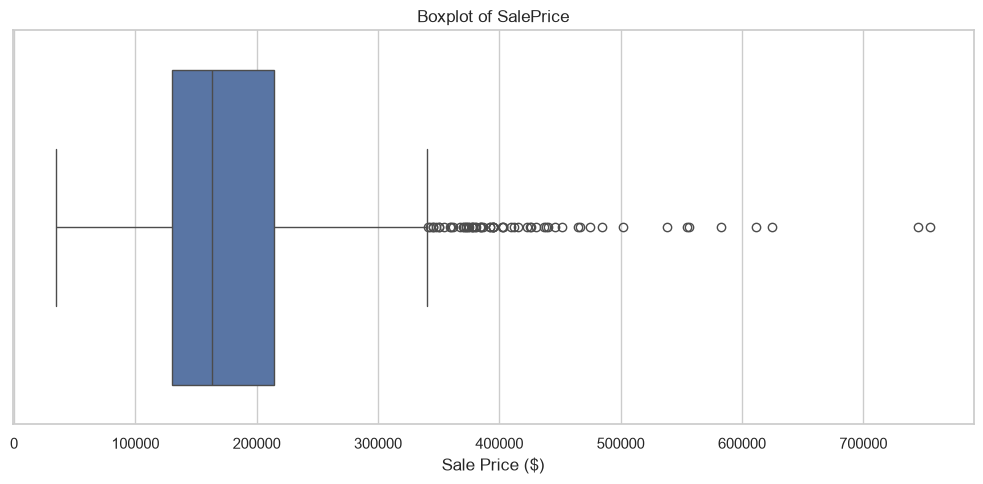

In [47]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_eda["SalePrice"])

plt.title("Boxplot of SalePrice")
plt.xlabel("Sale Price ($)")

plt.tight_layout()
plt.show()

## 8.3 Outlier Detection in GrLivArea

We apply the IQR method to GrLivArea to identify houses with unusually small or large above-ground living areas.

In [48]:
Q1_area = df_eda["GrLivArea"].quantile(0.25)
Q3_area = df_eda["GrLivArea"].quantile(0.75)

IQR_area = Q3_area - Q1_area

lower_area = Q1_area - 1.5 * IQR_area
upper_area = Q3_area + 1.5 * IQR_area

area_outliers = df_eda[
    (df_eda["GrLivArea"] < lower_area) |
    (df_eda["GrLivArea"] > upper_area)
]

print("GrLivArea Outlier Analysis")
print("-------------------------")
print("Q1:", Q1_area)
print("Q3:", Q3_area)
print("IQR:", IQR_area)
print("Lower Bound:", lower_area)
print("Upper Bound:", upper_area)
print("Number of Outliers:", len(area_outliers))

GrLivArea Outlier Analysis
-------------------------
Q1: 1129.5
Q3: 1776.75
IQR: 647.25
Lower Bound: 158.625
Upper Bound: 2747.625
Number of Outliers: 31


## 8.4 GrLivArea Outlier Visualization

We use a boxplot to visualize the distribution of above-ground living area and identify potential unusually large or small houses.

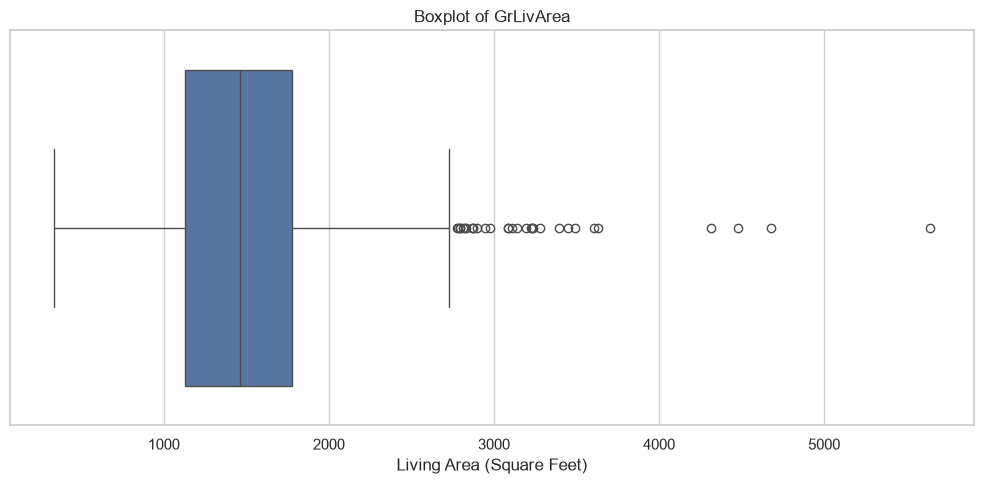

In [49]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_eda["GrLivArea"])

plt.title("Boxplot of GrLivArea")
plt.xlabel("Living Area (Square Feet)")

plt.tight_layout()
plt.show()

## 8.5 Outlier Summary

In this section, we summarize the potential outliers identified in SalePrice and GrLivArea using the IQR method. We do not remove these observations at this stage because outliers may represent genuine properties rather than incorrect data.

In [50]:
print("OUTLIER SUMMARY")
print("============================")
print("SalePrice Outliers:", len(price_outliers))
print("GrLivArea Outliers:", len(area_outliers))

print("\nDataset Shape:", df_eda.shape)

OUTLIER SUMMARY
SalePrice Outliers: 61
GrLivArea Outliers: 31

Dataset Shape: (1460, 81)


# 9. Feature Importance & Relationship Analysis

In this stage, we analyze the numerical features that have the strongest statistical relationships with SalePrice. We use correlation analysis to rank the features and visualize the most relevant variables.

## 9.1 Ranking Features by Correlation

We calculate the Pearson correlation coefficient between SalePrice and all numerical features. This helps us identify which numerical variables have the strongest linear relationships with house sale prices.

In [52]:
saleprice_corr = df_eda.select_dtypes(include="number").corr()["SalePrice"]

saleprice_corr = saleprice_corr.drop("SalePrice").sort_values(
    ascending=False
)

display(saleprice_corr)

OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePrice, dtype: float64

## 9.2 Top 15 Correlated Features

We visualize the 15 numerical features with the strongest positive correlations with SalePrice using a bar chart.

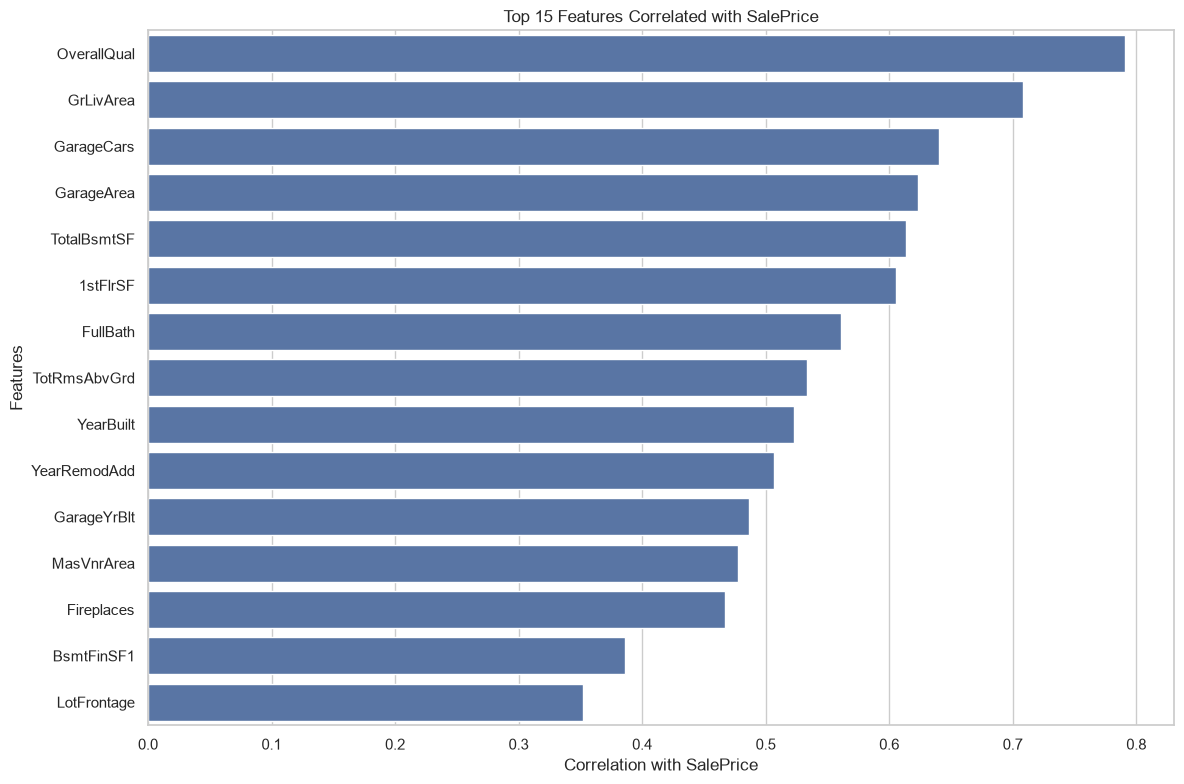

In [53]:
top_15_features = saleprice_corr.head(15)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=top_15_features.values,
    y=top_15_features.index
)

plt.title("Top 15 Features Correlated with SalePrice")
plt.xlabel("Correlation with SalePrice")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## 9.3 Features with Negative Correlation

We identify numerical features that have negative correlations with SalePrice. Negative correlation indicates that as one variable increases, SalePrice may tend to decrease.


In [54]:
negative_corr = saleprice_corr.sort_values(ascending=True).head(10)

display(negative_corr)

KitchenAbvGr    -0.135907
EnclosedPorch   -0.128578
MSSubClass      -0.084284
OverallCond     -0.077856
YrSold          -0.028923
LowQualFinSF    -0.025606
Id              -0.021917
MiscVal         -0.021190
BsmtHalfBath    -0.016844
BsmtFinSF2      -0.011378
Name: SalePrice, dtype: float64

## 9.4 Detailed Analysis of OverallQual

OverallQual is an important feature in the housing dataset. We visualize its relationship with SalePrice using a scatter plot to examine how house quality ratings relate to prices.

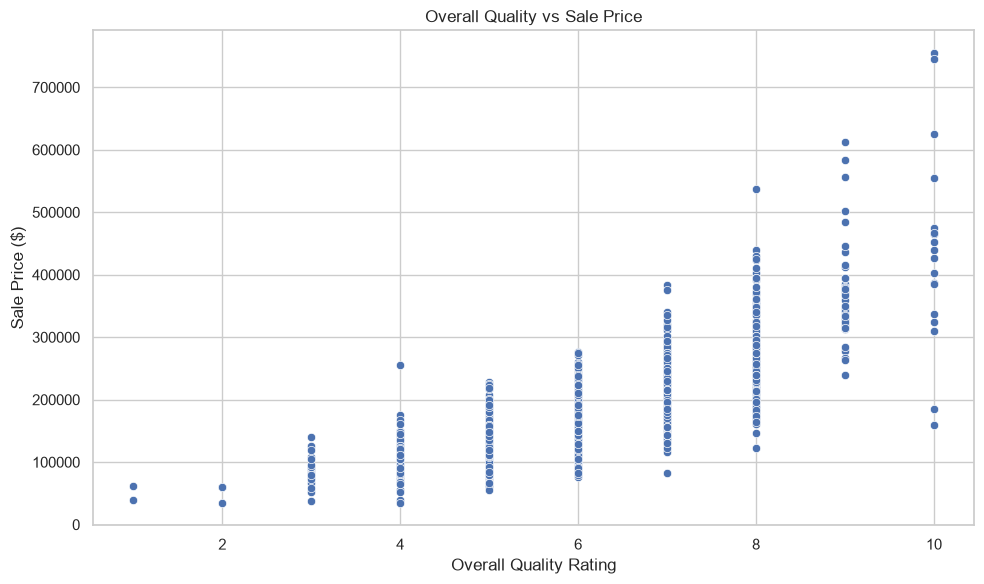

In [55]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_eda,
    x="OverallQual",
    y="SalePrice"
)

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality Rating")
plt.ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()

## 9.5 Detailed Analysis of GrLivArea

GrLivArea represents the above-ground living area of a house. We analyze this feature in detail because it often has a strong statistical relationship with SalePrice.

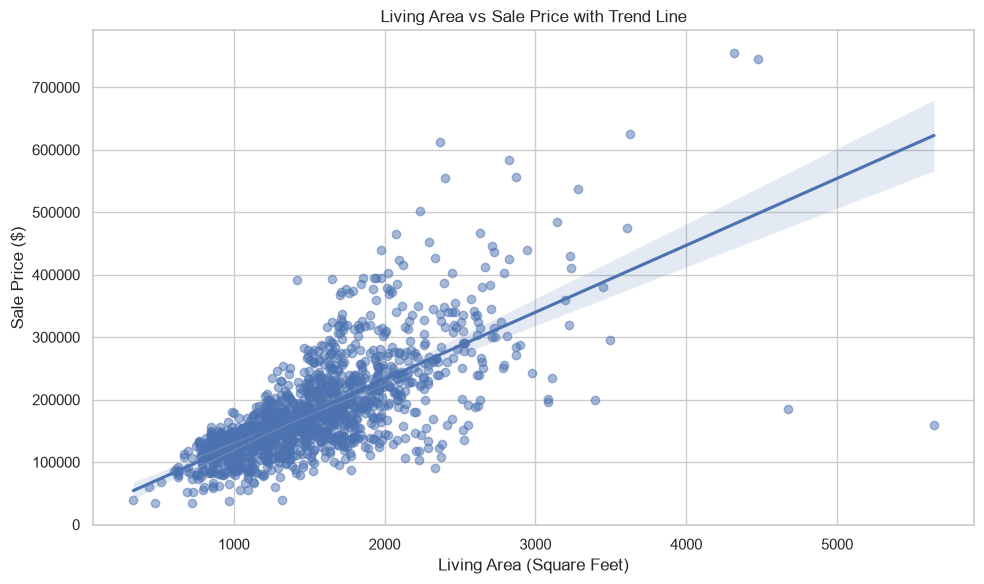

In [56]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_eda,
    x="GrLivArea",
    y="SalePrice",
    scatter_kws={"alpha": 0.5}
)

plt.title("Living Area vs Sale Price with Trend Line")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()

## 9.6 Feature Correlation Summary

We create a summary of the five numerical features with the strongest positive correlations with SalePrice. This helps us identify the most statistically relevant features for further analysis.

In [57]:
feature_summary = saleprice_corr.head(5).reset_index()

feature_summary.columns = [
    "Feature",
    "Correlation with SalePrice"
]

display(feature_summary)

,Feature,Correlation with SalePrice
0,OverallQual,0.790982
1,GrLivArea,0.708624
2,GarageCars,0.640409
3,GarageArea,0.623431
4,TotalBsmtSF,0.613581


# 10. Advanced Visualization & Insights

In this stage, we create advanced visualizations to explore relationships between house prices and important housing characteristics. These visualizations help identify pricing patterns across neighborhoods, house quality categories and property sizes.

## 10.1 Sale Price by Neighborhood

We compare house sale prices across different neighborhoods using a boxplot. This helps us understand how house prices vary depending on residential location.`

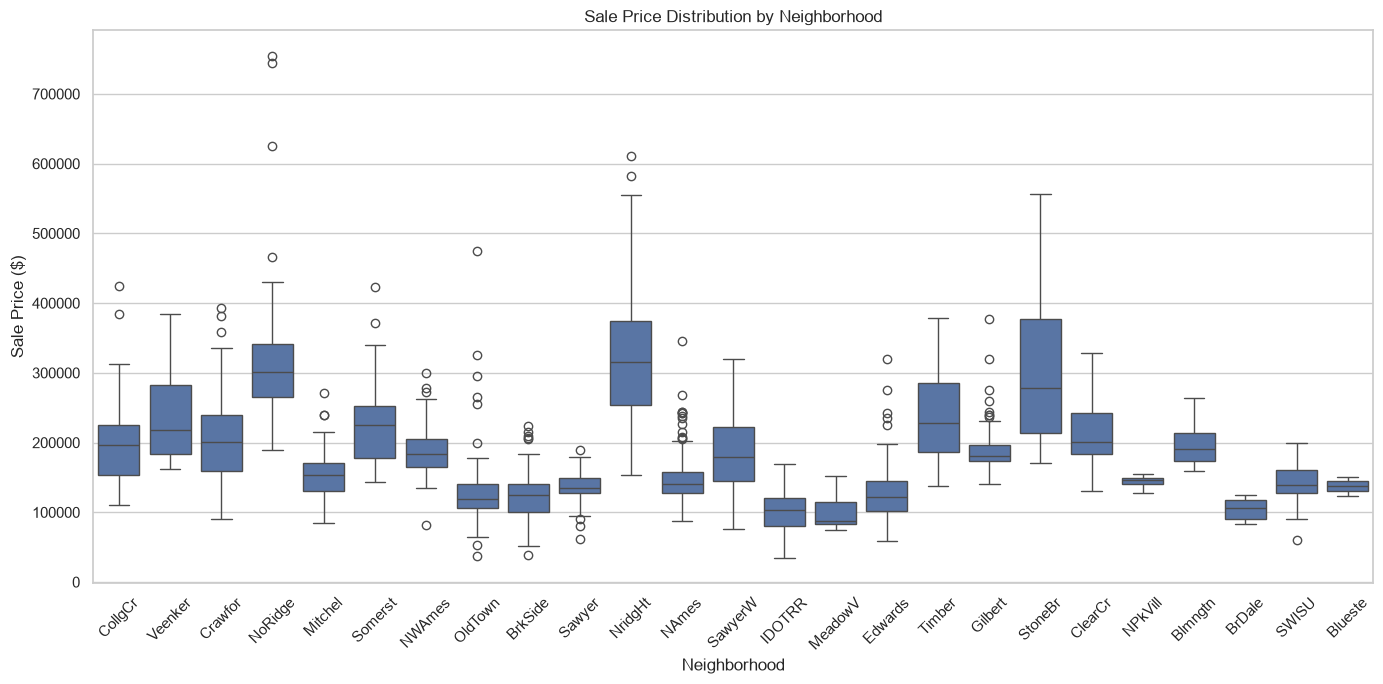

In [58]:
plt.figure(figsize=(14, 7))

sns.boxplot(data=df_eda, x="Neighborhood", y="SalePrice")

plt.title("Sale Price Distribution by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 10.2 Average Sale Price by Neighborhood

We calculate the average house sale price for each neighborhood and visualize the neighborhoods in descending order of average sale price.

In [59]:
neighborhood_prices = (
    df_eda.groupby("Neighborhood")["SalePrice"]
    .mean()
    .sort_values(ascending=False)
)

display(neighborhood_prices)

Neighborhood
NoRidge    335295.317073
NridgHt    316270.623377
StoneBr    310499.000000
Timber     242247.447368
Veenker    238772.727273
Somerst    225379.837209
ClearCr    212565.428571
Crawfor    210624.725490
CollgCr    197965.773333
Blmngtn    194870.882353
Gilbert    192854.506329
NWAmes     189050.068493
SawyerW    186555.796610
Mitchel    156270.122449
NAmes      145847.080000
NPkVill    142694.444444
SWISU      142591.360000
Blueste    137500.000000
Sawyer     136793.135135
OldTown    128225.300885
Edwards    128219.700000
BrkSide    124834.051724
BrDale     104493.750000
IDOTRR     100123.783784
MeadowV     98576.470588
Name: SalePrice, dtype: float64

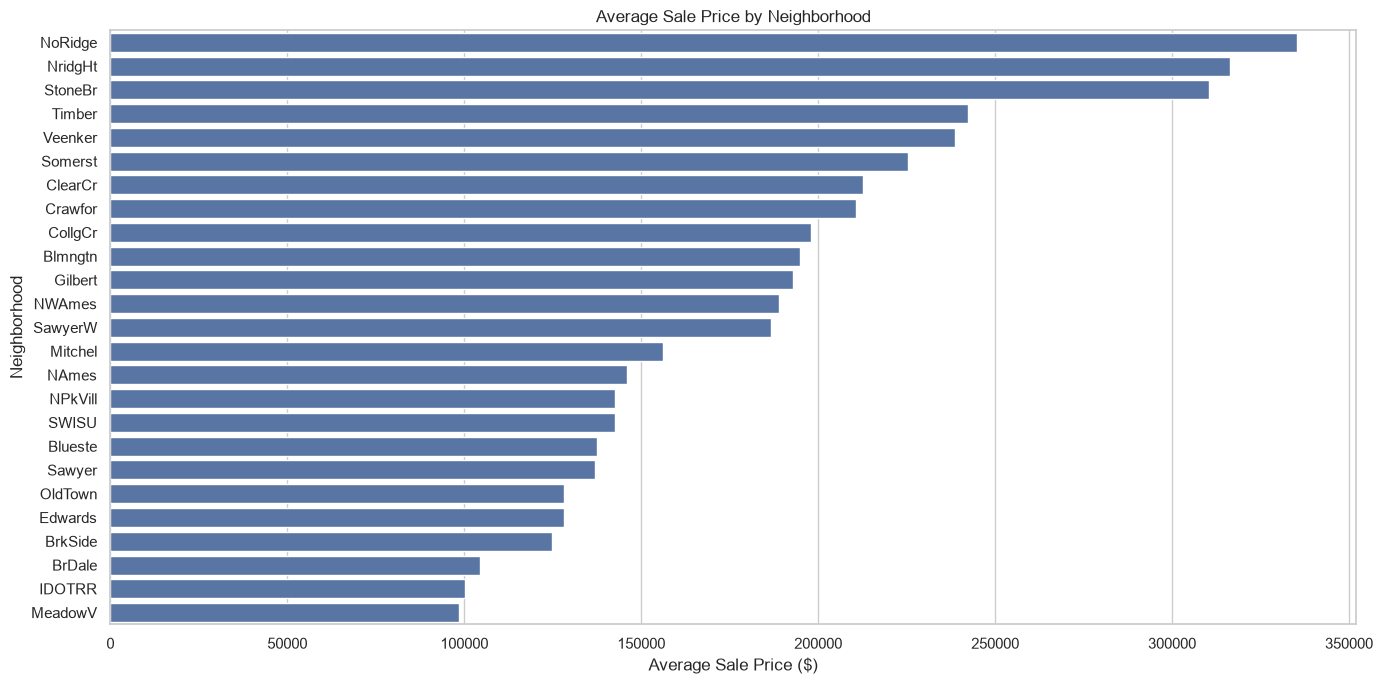

In [60]:
plt.figure(figsize=(14, 7))

sns.barplot(
    x=neighborhood_prices.values,
    y=neighborhood_prices.index
)

plt.title("Average Sale Price by Neighborhood")
plt.xlabel("Average Sale Price ($)")
plt.ylabel("Neighborhood")

plt.tight_layout()
plt.show()

## 10.3 House Quality and Sale Price

We use a violin plot to examine the distribution of house sale prices across different overall quality ratings. The plot helps us visualize price variation and distribution shape for each quality category.

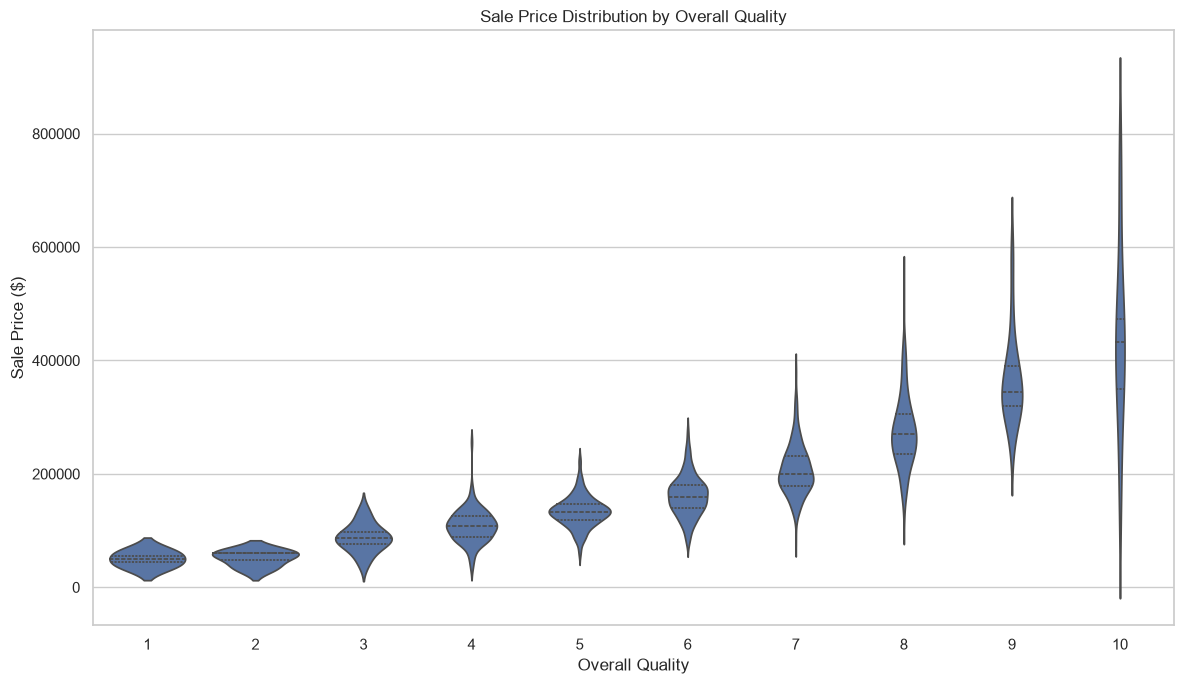

In [61]:
plt.figure(figsize=(12, 7))

sns.violinplot(
    data=df_eda,
    x="OverallQual",
    y="SalePrice",
    inner="quartile"
)

plt.title("Sale Price Distribution by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()

## 10.4 House Style and Sale Price

HouseStyle represents the architectural style of a house. We compare house sale prices across different house styles using a boxplot.

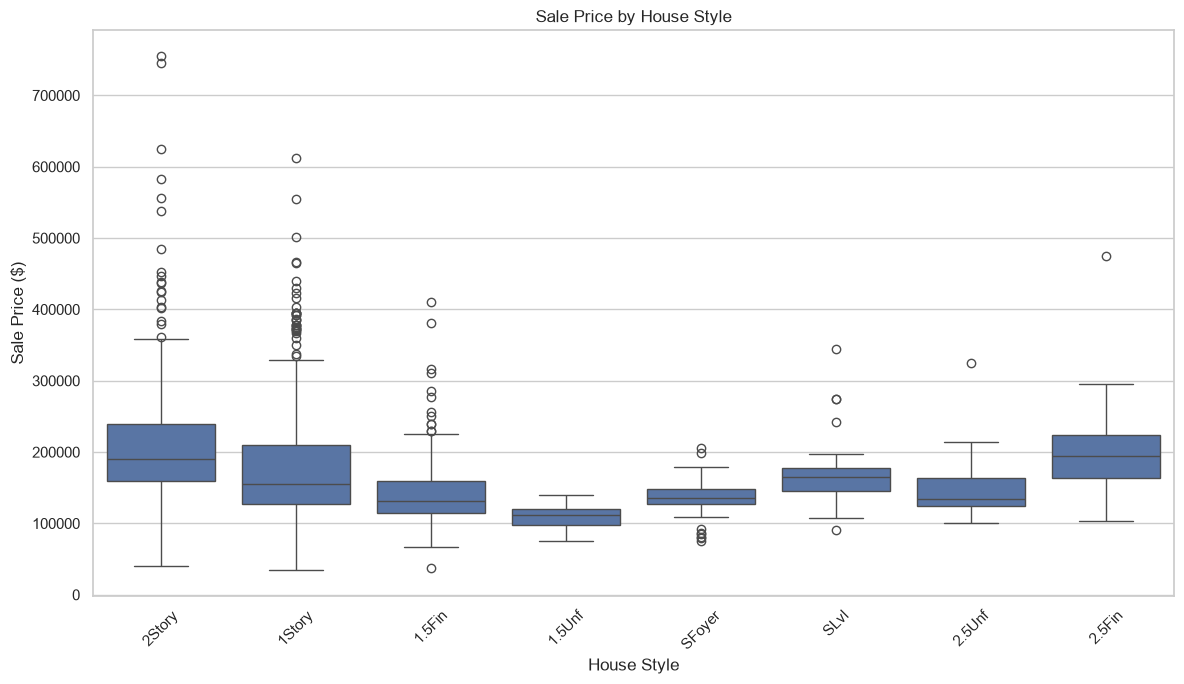

In [62]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df_eda,
    x="HouseStyle",
    y="SalePrice"
)

plt.title("Sale Price by House Style")
plt.xlabel("House Style")
plt.ylabel("Sale Price ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 10.5 Construction Year and Sale Price

We group houses by construction year and calculate the average sale price for each year. A line plot helps us observe changes in average house prices across construction years.

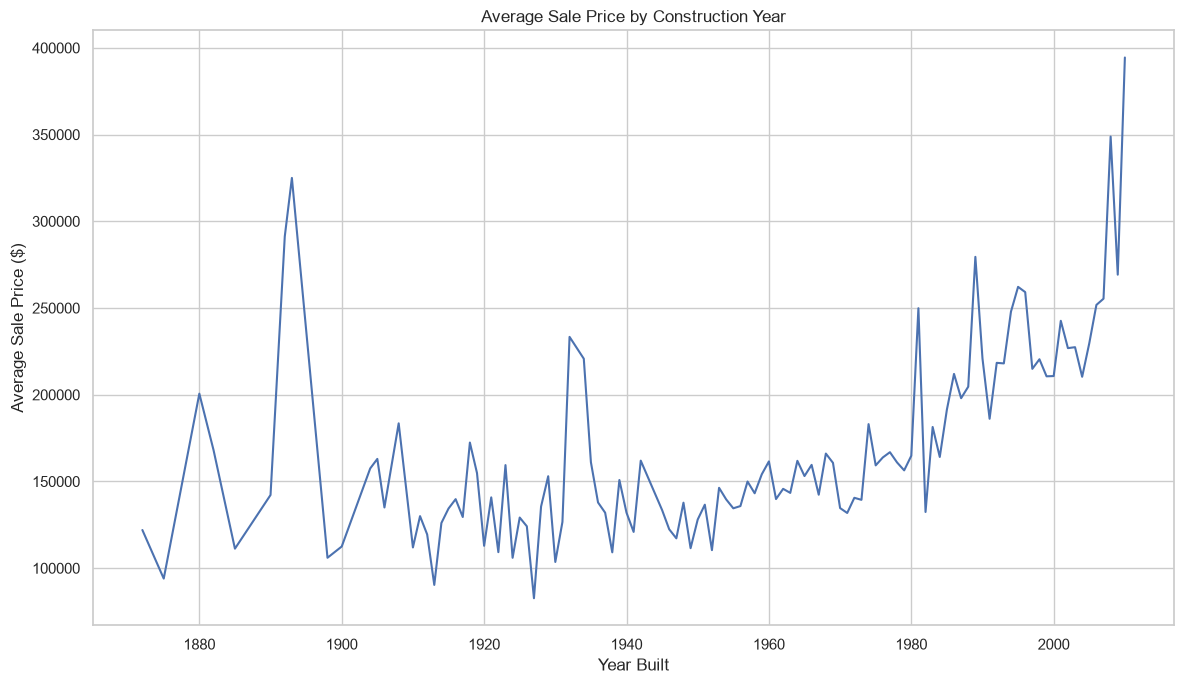

In [63]:
year_prices = (
    df_eda.groupby("YearBuilt")["SalePrice"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 7))

plt.plot(year_prices.index, year_prices.values)

plt.title("Average Sale Price by Construction Year")
plt.xlabel("Year Built")
plt.ylabel("Average Sale Price ($)")

plt.tight_layout()
plt.show()

## 10.6 Top 10 Neighborhoods by Average Sale Price

We identify the ten neighborhoods with the highest average sale prices and visualize them using a horizontal bar chart.

Neighborhood
NoRidge    335295.317073
NridgHt    316270.623377
StoneBr    310499.000000
Timber     242247.447368
Veenker    238772.727273
Somerst    225379.837209
ClearCr    212565.428571
Crawfor    210624.725490
CollgCr    197965.773333
Blmngtn    194870.882353
Name: SalePrice, dtype: float64

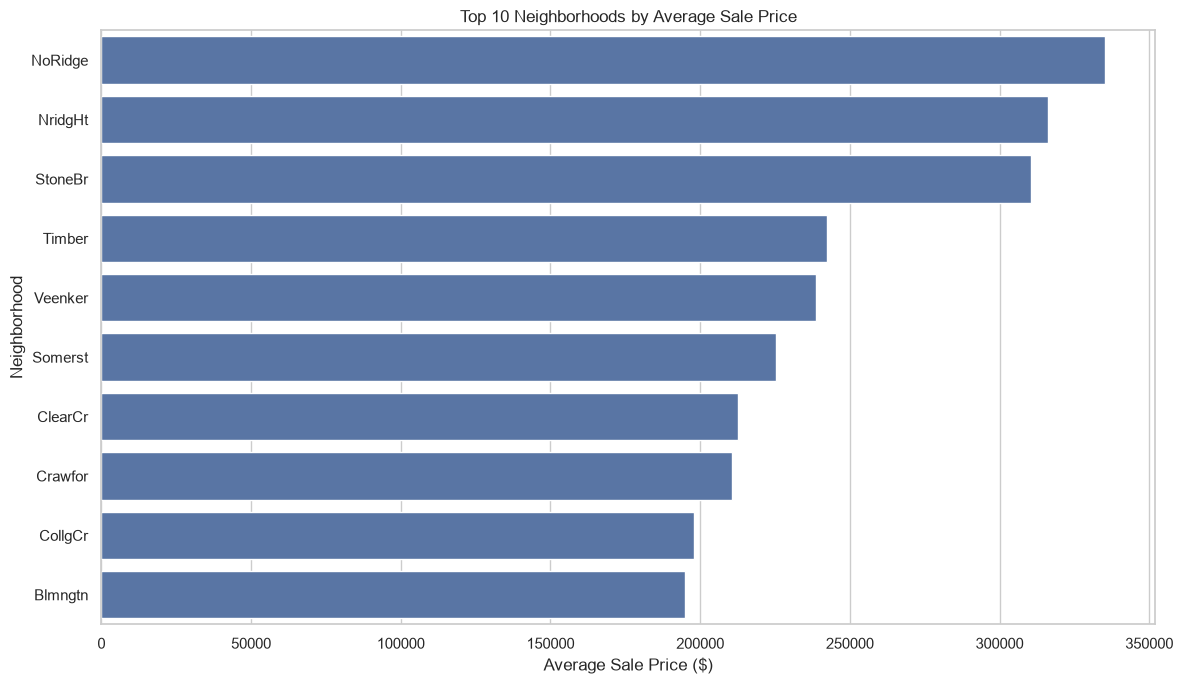

In [64]:
top_10_neighborhoods = neighborhood_prices.head(10)

display(top_10_neighborhoods)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_10_neighborhoods.values,
    y=top_10_neighborhoods.index
)

plt.title("Top 10 Neighborhoods by Average Sale Price")
plt.xlabel("Average Sale Price ($)")
plt.ylabel("Neighborhood")

plt.tight_layout()
plt.show()

# 11. Final EDA Summary & Key Findings

In this stage, we summarize the important findings obtained from the Exploratory Data Analysis of the Ames Housing Dataset. We review the major patterns, relationships, distributions and insights discovered throughout the project.

In [65]:
print("=" * 60)
print("FINAL EDA STATISTICAL SUMMARY")
print("=" * 60)

print("\n1. DATASET INFORMATION")
print("Total rows:", df_eda.shape[0])
print("Total columns:", df_eda.shape[1])

print("\n2. SALE PRICE INFORMATION")
print("Average Sale Price:", round(df_eda["SalePrice"].mean(), 2))
print("Median Sale Price:", df_eda["SalePrice"].median())
print("Minimum Sale Price:", df_eda["SalePrice"].min())
print("Maximum Sale Price:", df_eda["SalePrice"].max())

print("\n3. TOP CORRELATED FEATURES")

numeric_df = df_eda.select_dtypes(include=np.number)

correlations = numeric_df.corr()["SalePrice"].drop("SalePrice")
top_features = correlations.sort_values(ascending=False).head(5)

display(top_features)

print("\n4. TOP 5 NEIGHBORHOODS BY AVERAGE PRICE")

top_neighborhoods = (
    df_eda.groupby("Neighborhood")["SalePrice"]
    .mean()
    .sort_values(ascending=False)
    .head(5)
)

display(top_neighborhoods)

print("\n5. PROJECT SUMMARY GENERATED SUCCESSFULLY!")

FINAL EDA STATISTICAL SUMMARY

1. DATASET INFORMATION
Total rows: 1460
Total columns: 81

2. SALE PRICE INFORMATION
Average Sale Price: 180921.2
Median Sale Price: 163000.0
Minimum Sale Price: 34900
Maximum Sale Price: 755000

3. TOP CORRELATED FEATURES


OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
GarageArea     0.623431
TotalBsmtSF    0.613581
Name: SalePrice, dtype: float64


4. TOP 5 NEIGHBORHOODS BY AVERAGE PRICE


Neighborhood
NoRidge    335295.317073
NridgHt    316270.623377
StoneBr    310499.000000
Timber     242247.447368
Veenker    238772.727273
Name: SalePrice, dtype: float64


5. PROJECT SUMMARY GENERATED SUCCESSFULLY!


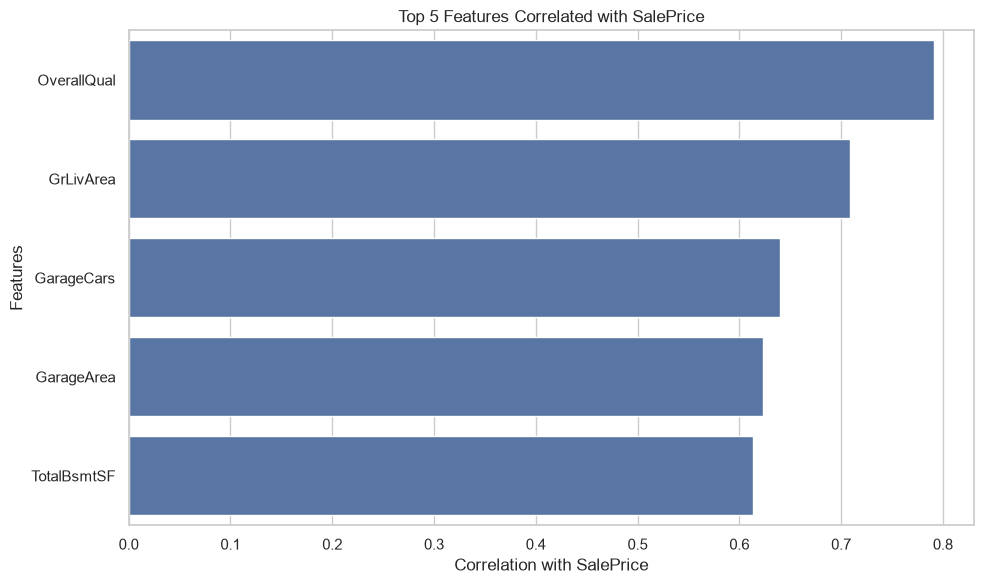

In [66]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_features.values,
    y=top_features.index
)

plt.title("Top 5 Features Correlated with SalePrice")
plt.xlabel("Correlation with SalePrice")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## Final Conclusion

Exploratory Data Analysis was successfully performed on the Ames Housing Dataset containing 1,460 records and 81 columns.

The analysis helped identify the distribution of house prices, missing values, outliers and relationships between different housing features and SalePrice.

Overall Quality, above-ground living area and neighborhood were among the important features associated with house prices. Different visualizations and statistical methods helped understand the dataset and identify patterns.

This EDA project provides a foundation for further data analysis and future machine learning models for house price prediction.

# 12. Final Project Preparation & Deliverables

In this final stage, we validate the complete notebook, organize the project files and prepare the final deliverables. The objective is to ensure that the EDA project is clean, properly documented and ready for submission or presentation.